<a href="https://colab.research.google.com/github/amasha-sinhalagoda/J26-IT-334/blob/model%2Fcp_landslide/Landslide_Comparison_Strength.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This notebook checks if our landslide models are reliable and if they perform better than the current NBRI hazard map. I evaluate three models using spatial cross-validation and a block-bootstrap to make sure the results are stable. This helps us confirm if the machine learning approach adds real value for Nuwara Eliya District.

In [3]:
from google.colab import files
uploaded = files.upload()
print(list(uploaded.keys()))

Saving static_clean_step1.csv to static_clean_step1.csv
['static_clean_step1.csv']


In [4]:
STATIC = find("static_clean_step1.csv")
print("Static:", STATIC)

st = pd.read_csv(STATIC)
print(st.shape, "| has bench_lhmp_class:", "bench_lhmp_class" in st.columns)

Static: static_clean_step1.csv
(5437, 17) | has bench_lhmp_class: True


I start by checking the baseline NBRI hazard map. I map the existing classes to our dynamic points to see how well they correlate with actual landslide occurrences.

In [5]:
!pip install lightgbm xgboost -q

import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

sns.set_theme(style="whitegrid")
SEED = 42

def find(name):
    for p in [Path("."), Path("/content"), Path("data/processed"), Path("../data/processed")]:
        if (p / name).exists(): return p / name
    return None

DATA   = find("landslide_dynamic_ml_dataset_terrain.csv")
STATIC = find("static_clean_step1.csv")
OUT    = DATA.parent / "outputs_step2"; OUT.mkdir(exist_ok=True)
print("Dynamic:", DATA, "| Static:", STATIC)

raw    = pd.read_csv(DATA)
y      = raw["dynamic_label"].values
folds0 = raw["fold"].values
blocks = raw["block_id"].values

SOIL    = [c for c in raw.columns if c.startswith("soil_")]
TERRAIN = ["elevation_m", "slope_deg"]
FEATS   = SOIL + TERRAIN
X = raw[FEATS]
print("Rows:", len(raw), "| features:", len(FEATS), "| blocks:", len(set(blocks)))

Dynamic: landslide_dynamic_ml_dataset_terrain.csv | Static: static_clean_step1.csv
Rows: 958 | features: 12 | blocks: 203


In [6]:
lhmp = raw["static_index"].astype(int).map(st["bench_lhmp_class"])
ok   = lhmp.notna().values
print(f"Rows with an NBRI class: {ok.sum()} of {len(raw)}")

rate = (pd.DataFrame({"class": lhmp[ok], "landslide": y[ok]})
        .groupby("class")["landslide"].agg(n="size", landslide_rate="mean").round(2))
display(rate)

pooled = roc_auc_score(y[ok], lhmp[ok])
per_fold = []
for k in np.unique(folds0):
    m = ok & (folds0 == k)
    if len(np.unique(y[m])) == 2: per_fold.append(roc_auc_score(y[m], lhmp[m]))
nbri = dict(pooled_auc=pooled, n=int(ok.sum()))
print(f"NBRI AUC pooled = {pooled:.3f} | per-fold = {np.mean(per_fold):.3f} +/- {np.std(per_fold, ddof=1):.3f}")

Rows with an NBRI class: 937 of 958


,n,landslide_rate
class,,
1.0,223,0.40
2.0,483,0.49
3.0,162,0.59
4.0,69,0.64


NBRI AUC pooled = 0.576 | per-fold = 0.566 +/- 0.067


The NBRI class covers 937 out of 958 points. The actual landslide rate rises from 40% in class 1 to 64% in class 4. However, the pooled AUC is only 0.576, which shows that this map ranks risk only weakly.

## Step 1: Model Setup

I define the models and the cross-validation setup here. I use spatial block folds to make sure our training and testing points are from different geographic areas.

In [8]:
def make_model(name, seed):
    if name == "Logistic Regression":
        return make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=3000, class_weight="balanced", random_state=seed))
    if name == "XGBoost":
        return XGBClassifier(n_estimators=250, max_depth=3, learning_rate=0.04, subsample=0.8, colsample_bytree=0.8,
                             min_child_weight=5, reg_lambda=5, eval_metric="logloss", n_jobs=2, random_state=seed)
    if name == "LightGBM":
        return LGBMClassifier(n_estimators=250, max_depth=3, num_leaves=8, learning_rate=0.04, subsample=0.8, subsample_freq=1,
                              colsample_bytree=0.8, min_child_samples=20, reg_lambda=5, class_weight="balanced",
                              verbose=-1, n_jobs=2, random_state=seed)
MODELS = ["Logistic Regression", "XGBoost", "LightGBM"]

def block_folds(seed, n_folds=5):
    rng = np.random.default_rng(seed)
    ub = np.array(sorted(set(blocks))); rng.shuffle(ub)
    mapping = {b: i % n_folds for i, b in enumerate(ub)}
    return np.array([mapping[b] for b in blocks])

def run_cv(model_name, fold_ids, seed):
    p = np.zeros(len(raw))
    for k in np.unique(fold_ids):
        tr, te = fold_ids != k, fold_ids == k
        p[te] = make_model(model_name, seed).fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
    return p
print("Models are ready")

Models are ready


## Step 2: Repeated Spatial Cross-Validation

I run the cross-validation five times with different random seeds. This checks if the model performance changes a lot when the spatial block splits change.

In [9]:
SEEDS = [11, 22, 33, 44, 55]
rows = []
for s in SEEDS:
    f = block_folds(s)
    for m in MODELS:
        p = run_cv(m, f, s)
        rows.append(dict(seed=s, model=m, auc=roc_auc_score(y, p), ap=average_precision_score(y, p)))
rep = pd.DataFrame(rows)
rep_summary = rep.groupby("model").agg(AUC_mean=("auc","mean"), AUC_std=("auc","std"),
                                       AP_mean=("ap","mean")).round(3).loc[MODELS]
display(rep_summary)
rep.pivot(index="seed", columns="model", values="auc")[MODELS].round(3)

,AUC_mean,AUC_std,AP_mean
model,,,
Logistic Regression,0.790,0.004,0.742
XGBoost,0.820,0.003,0.761
LightGBM,0.821,0.004,0.762


model,Logistic Regression,XGBoost,LightGBM
seed,,,
11,0.790,0.819,0.823
22,0.797,0.820,0.822
33,0.790,0.821,0.826
44,0.787,0.815,0.816
55,0.785,0.824,0.819


The results are very stable across different splits, with a standard deviation of only 0.004. LightGBM gets a mean AUC of 0.821, XGBoost gets 0.820, and Logistic Regression gets 0.790.

## Step 3: Block-Bootstrap Uncertainty

I use block bootstrapping with 1000 resamples to calculate 95% confidence intervals and compare the models directly.

In [10]:
oof = {m: run_cv(m, folds0, SEED) for m in MODELS}

ub = np.array(sorted(set(blocks)))
idx_by_block = {b: np.where(blocks == b)[0] for b in ub}
rng = np.random.default_rng(SEED)
boot = {m: [] for m in MODELS}
for _ in range(1000):
    chosen = rng.choice(ub, size=len(ub), replace=True)
    idx = np.concatenate([idx_by_block[b] for b in chosen])
    if len(np.unique(y[idx])) < 2: continue
    for m in MODELS: boot[m].append(roc_auc_score(y[idx], oof[m][idx]))
boot = {m: np.array(v) for m, v in boot.items()}

ci = pd.DataFrame({m: dict(AUC=roc_auc_score(y, oof[m]),
                           CI_low=np.percentile(boot[m], 2.5),
                           CI_high=np.percentile(boot[m], 97.5)) for m in MODELS}).T.round(3)
display(ci)

pairs = [("XGBoost","Logistic Regression"), ("LightGBM","Logistic Regression"), ("XGBoost","LightGBM")]
diff_df = pd.DataFrame([dict(comparison=f"{a} - {b}", mean_diff=(boot[a]-boot[b]).mean(),
                             CI_low=np.percentile(boot[a]-boot[b], 2.5),
                             CI_high=np.percentile(boot[a]-boot[b], 97.5)) for a, b in pairs]).round(3)
diff_df["excludes_zero"] = (diff_df.CI_low > 0) | (diff_df.CI_high < 0)
display(diff_df)

,AUC,CI_low,CI_high
Logistic Regression,0.797,0.754,0.836
XGBoost,0.823,0.777,0.858
LightGBM,0.822,0.778,0.858


,comparison,mean_diff,CI_low,CI_high,excludes_zero
0,XGBoost - Logistic Regression,0.026,-0.010,0.059,False
1,LightGBM - Logistic Regression,0.025,-0.009,0.058,False
2,XGBoost - LightGBM,0.000,-0.005,0.006,False


The intervals overlap heavily. The difference between XGBoost and Logistic Regression is 0.026, but the interval includes zero. This means the tree-based models are not conclusively better than the linear model.

## Step 4: Calibration and Brier Scores

I calculate the Brier scores and plot the calibration curves. This helps us see if the predicted probabilities match the real landslide rates.

,Logistic Regression,XGBoost,LightGBM
Brier,0.183,0.17,0.172


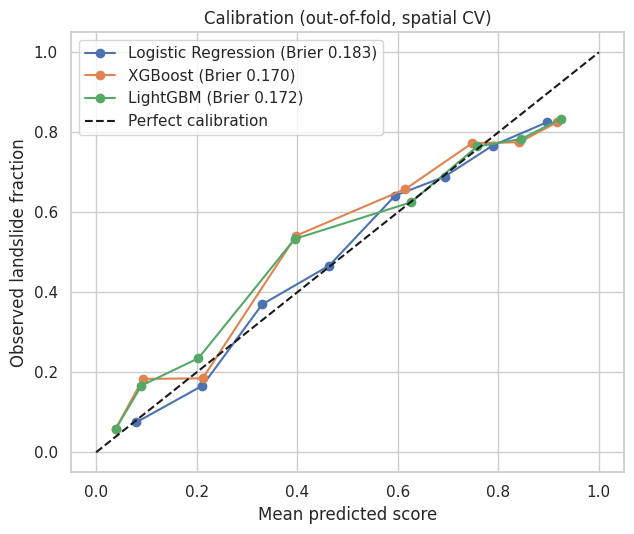

In [11]:
brier = pd.Series({m: brier_score_loss(y, oof[m]) for m in MODELS}, name="Brier").round(3)
display(brier.to_frame().T)

plt.figure(figsize=(6.5, 5.5))
for m in MODELS:
    frac, mean_p = calibration_curve(y, oof[m], n_bins=8, strategy="quantile")
    plt.plot(mean_p, frac, marker="o", label=f"{m} (Brier {brier[m]:.3f})")
plt.plot([0,1],[0,1],"k--",label="Perfect calibration")
plt.xlabel("Mean predicted score"); plt.ylabel("Observed landslide fraction")
plt.title("Calibration (out-of-fold, spatial CV)"); plt.legend(); plt.tight_layout(); plt.show()

The Brier scores are around 0.170, which is much better than the 0.250 we would get by guessing. The calibration curve is close to the diagonal, though it slightly under-rates risk in the middle range. Because our data is balanced 50-50, these are relative susceptibility scores rather than actual real-world probabilities.